# 08groundcheck: does the model agree with real stations?

Part B of PF5. Compares GEOS-FP daily PM2.5 (`05season`) with ground measurements.

| Section | Source | What |
|---|---|---|
| 2 | Singapore National Environment Agency, via data.gov.sg (official) | hourly PM2.5 for five regions, every day of the season |
| 3 | OpenAQ (free, collects stations worldwide) | which stations near Kuala Lumpur and near the fire areas have PM2.5 for the season; their daily means |
| 4 | Comparison | daily model vs stations: correlation, bias, ratio; time series and scatter charts |

**Why this matters.** Everything in the case study about people's air rests on the model. A comparison with stations says how far it can be trusted, and whether it tends to be too high or too low. A model grid cell (about 55 km) is compared with a point, so some difference is expected even for a perfect model.

**Reference monitors and low-cost sensors.** OpenAQ marks each location as a reference monitor or not ("isMonitor"). Low-cost sensors often read high in humid, hazy air; the notebook keeps the two apart.

Downloads are small (a few MB) and take a few minutes. Results are saved, and a re-run skips days already fetched.

## Section 0: settings

In [1]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
KEYS_FILE = PROJECT_DIR / "config" / "keys.toml"
SEASON_DIR = PROJECT_DIR / "data" / "processed" / "season"
GROUND_DIR = PROJECT_DIR / "data" / "raw" / "ground"
FIG_DIR = SEASON_DIR / "figures"

SEASON_START = "2026-08-01"  # <-
SEASON_END = "2026-10-25"  # <-

# Places searched in OpenAQ: (lat, lon); radius in metres (OpenAQ allows up to 25,000)
SEARCH_PLACES = {"Kuala Lumpur": (3.14, 101.69), "Pekanbaru": (0.51, 101.45), "Palembang": (-2.98, 104.76), "Pontianak": (-0.03, 109.33), "Palangka Raya": (-2.21, 113.92), "Jakarta": (-6.20, 106.82)}  # <-
SEARCH_RADIUS_M = 25000  # <-
MIN_DAYS = 20  # <- a station needs at least this many days with data in the season to be compared
MIN_COVERAGE_PCT = 75  # <- a station day counts if at least this share of its hours were measured

## Section 1: imports and keys

In [2]:
import time
import tomllib
import requests
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

GROUND_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.facecolor"] = "#fcfcfb"
plt.rcParams["axes.facecolor"] = "#fcfcfb"
plt.rcParams["axes.edgecolor"] = "#a8a7a2"
plt.rcParams["font.size"] = 10
with open(KEYS_FILE, "rb") as f:
    KEYS = tomllib.load(f)
OPENAQ_KEY = KEYS.get("openaq", {}).get("key", "").strip()
SG_KEY = KEYS.get("datagovsg", {}).get("key", "").strip()
print("OpenAQ key filled in:", len(OPENAQ_KEY) > 0, "  data.gov.sg key filled in:", len(SG_KEY) > 0)

DAYS = pd.date_range(SEASON_START, SEASON_END, freq="D")
geos = xr.open_dataset(SEASON_DIR / "geosfp_daily.nc")[["pm25", "smoke"]].load()


def model_at(lat, lon):
    return geos["pm25"].interp(lat=lat, lon=lon).to_series().rename("model_pm25")

OpenAQ key filled in: True   data.gov.sg key filled in: False


## Section 2: Singapore (NEA, data.gov.sg)

One request per day. Each answer holds the hourly PM2.5 (1-hour mean, micrograms per m3) for the north, south, east, west and central regions and the national figure. Times are Singapore time (UTC+8); daily means here are for Singapore calendar days, while GEOS-FP days are UTC days, an 8-hour offset that matters little for daily means.

In [3]:
SG_URL = "https://api-open.data.gov.sg/v2/real-time/api/pm25"
sg_file = GROUND_DIR / "singapore_pm25_hourly.csv"
have = pd.read_csv(sg_file, parse_dates=["timestamp"]) if sg_file.exists() else pd.DataFrame()
have_days = set(pd.to_datetime(have["sg_date"]).dt.normalize()) if len(have) else set()
headers = {"x-api-key": SG_KEY} if SG_KEY else {}
rows = []
regions_meta = {}
for day in DAYS:
    if day in have_days:
        continue
    params = {"date": f"{day:%Y-%m-%d}"}
    while True:
        r = requests.get(SG_URL, params=params, headers=headers, timeout=60)
        if r.status_code == 429:
            time.sleep(10)
            continue
        break
    if r.status_code != 200:
        print(f"{day:%d %b}: HTTP {r.status_code} {r.text[:150]}")
        if r.status_code in (401, 403):
            print("data.gov.sg asks for an API key: get one free at data.gov.sg and put it under [datagovsg] in config/keys.toml")
            break
        continue
    data = r.json().get("data", {})
    for m in data.get("regionMetadata", []):
        regions_meta[m["name"]] = (m["labelLocation"]["latitude"], m["labelLocation"]["longitude"])
    for item in data.get("items", []):
        rd = item.get("readings", {}).get("pm25_one_hourly", {})
        for region, value in rd.items():
            rows.append({"sg_date": day, "timestamp": item.get("timestamp"), "region": region, "pm25": value})
    time.sleep(0.3)
if rows:
    new = pd.DataFrame(rows)
    new["timestamp"] = pd.to_datetime(new["timestamp"], utc=True).dt.tz_convert("Asia/Singapore").dt.tz_localize(None)
    allsg = pd.concat([have, new], ignore_index=True) if len(have) else new
    allsg = allsg.drop_duplicates(["timestamp", "region"]).sort_values(["timestamp", "region"])
    allsg.to_csv(sg_file, index=False)
else:
    allsg = have
if regions_meta:
    pd.DataFrame([(k, v[0], v[1]) for k, v in regions_meta.items()], columns=["region", "lat", "lon"]).to_csv(GROUND_DIR / "singapore_regions.csv", index=False)
print("Singapore hourly rows:", len(allsg), " days:", allsg["sg_date"].nunique() if len(allsg) else 0, " regions:", sorted(allsg["region"].unique()) if len(allsg) else [])

Singapore hourly rows: 10320  days: 86  regions: ['central', 'east', 'north', 'south', 'west']


In [4]:
# Singapore daily means per region and the national figure, matched with GEOS-FP
sg_pairs = pd.DataFrame(columns=["date", "place", "source", "is_monitor", "station_pm25", "model_pm25"])
if not sg_file.exists():
    print("No Singapore data yet: check the messages of the cell above.")
else:
    sg = pd.read_csv(sg_file, parse_dates=["timestamp", "sg_date"])
    meta = pd.read_csv(GROUND_DIR / "singapore_regions.csv").set_index("region")
    sg_daily = sg.groupby(["region", sg["timestamp"].dt.normalize()])["pm25"].agg(["mean", "count"]).reset_index().rename(columns={"timestamp": "date", "mean": "station_pm25", "count": "hours"})
    sg_daily = sg_daily[sg_daily["hours"] >= 24 * MIN_COVERAGE_PCT / 100]
    pairs = []
    for region, g in sg_daily.groupby("region"):
        lat, lon = meta.loc[region, ["lat", "lon"]] if region in meta.index else meta.loc["central", ["lat", "lon"]]
        m = model_at(lat, lon)
        d = g.set_index("date").join(m, how="inner")
        d["place"] = f"Singapore {region}"
        d["source"] = "NEA (reference)"
        d["is_monitor"] = True
        pairs.append(d.reset_index()[["date", "place", "source", "is_monitor", "station_pm25", "model_pm25"]])
    sg_pairs = pd.concat(pairs, ignore_index=True)
    print("Singapore station-days matched with the model:", len(sg_pairs))

Singapore station-days matched with the model: 430


## Section 3: OpenAQ stations near Kuala Lumpur and the fire areas

First a list of every OpenAQ location with a PM2.5 sensor within the radius of each place (saved to `openaq_locations.csv`), then the daily means of those that report during the season.

In [5]:
OA = "https://api.openaq.org/v3"
OA_HEADERS = {"X-API-Key": OPENAQ_KEY}


def oa_get(path, params):
    for attempt in range(5):
        r = requests.get(OA + path, params=params, headers=OA_HEADERS, timeout=60)
        if r.status_code == 429:
            time.sleep(15)
            continue
        return r
    return r


loc_rows = []
for place, (lat, lon) in SEARCH_PLACES.items():
    r = oa_get("/locations", {"coordinates": f"{lat},{lon}", "radius": SEARCH_RADIUS_M, "limit": 1000})
    if r.status_code == 422:
        r = oa_get("/locations", {"coordinates": f"{lon},{lat}", "radius": SEARCH_RADIUS_M, "limit": 1000})
    if r.status_code != 200:
        print(f"{place}: HTTP {r.status_code} {r.text[:150]}")
        continue
    found = r.json().get("results", [])
    n_pm = 0
    for loc in found:
        for s in loc.get("sensors", []):
            if s.get("parameter", {}).get("name") != "pm25":
                continue
            n_pm += 1
            loc_rows.append({"place": place, "location_id": loc["id"], "location": loc.get("name"), "provider": (loc.get("provider") or {}).get("name"), "is_monitor": loc.get("isMonitor"), "lat": loc["coordinates"]["latitude"], "lon": loc["coordinates"]["longitude"], "sensor_id": s["id"], "first": (loc.get("datetimeFirst") or {}).get("utc"), "last": (loc.get("datetimeLast") or {}).get("utc")})
    print(f"{place}: {len(found)} locations, {n_pm} PM2.5 sensors")
    time.sleep(1.1)
locs = pd.DataFrame(loc_rows)
locs.to_csv(GROUND_DIR / "openaq_locations.csv", index=False)
if len(locs):
    locs["last"] = pd.to_datetime(locs["last"], utc=True, errors="coerce").dt.tz_localize(None)
    locs["first"] = pd.to_datetime(locs["first"], utc=True, errors="coerce").dt.tz_localize(None)
    active = locs[(locs["last"] >= DAYS[0]) & (locs["first"] <= DAYS[-1])]
    print()
    print(f"PM2.5 sensors active during the season: {len(active)} of {len(locs)}")
    print(active.groupby(["place", "is_monitor"]).size().rename("sensors").to_string())
else:
    active = locs

Kuala Lumpur: 21 locations, 21 PM2.5 sensors
Pekanbaru: 0 locations, 0 PM2.5 sensors
Palembang: 4 locations, 4 PM2.5 sensors
Pontianak: 0 locations, 0 PM2.5 sensors
Palangka Raya: 37 locations, 37 PM2.5 sensors
Jakarta: 31 locations, 28 PM2.5 sensors

PM2.5 sensors active during the season: 26 of 90
place         is_monitor
Jakarta       False          8
Kuala Lumpur  False         14
Palembang     False          4


In [6]:
oa_file = GROUND_DIR / "openaq_daily.csv"
done_ids = set(pd.read_csv(oa_file)["sensor_id"]) if oa_file.exists() else set()
new_rows = []
for _, s in active.iterrows():
    if s["sensor_id"] in done_ids:
        continue
    r = oa_get(f"/sensors/{s['sensor_id']}/days", {"datetime_from": f"{DAYS[0]:%Y-%m-%d}", "datetime_to": f"{DAYS[-1] + pd.Timedelta(days=1):%Y-%m-%d}", "limit": 1000})
    if r.status_code != 200:
        print(f"sensor {s['sensor_id']}: HTTP {r.status_code}")
        continue
    for d in r.json().get("results", []):
        cov = (d.get("coverage") or {}).get("percentComplete")
        new_rows.append({"sensor_id": s["sensor_id"], "date": d["period"]["datetimeFrom"]["utc"][:10], "station_pm25": d.get("value"), "coverage_pct": cov})
    time.sleep(1.1)
if new_rows:
    new = pd.DataFrame(new_rows)
    oa_daily = pd.concat([pd.read_csv(oa_file), new], ignore_index=True) if oa_file.exists() else new
    oa_daily.to_csv(oa_file, index=False)
oa_daily = pd.read_csv(oa_file, parse_dates=["date"]) if oa_file.exists() else pd.DataFrame(columns=["sensor_id", "date", "station_pm25", "coverage_pct"])
print("OpenAQ sensor-days downloaded:", len(oa_daily))

oa_pairs = []
for _, s in active.iterrows():
    d = oa_daily[oa_daily["sensor_id"] == s["sensor_id"]].copy()
    d = d[(d["coverage_pct"].fillna(100) >= MIN_COVERAGE_PCT) & (d["station_pm25"] >= 0) & (d["station_pm25"] < 1000)]
    if len(d) < MIN_DAYS:
        continue
    m = model_at(s["lat"], s["lon"])
    d = d.set_index("date").join(m, how="inner").reset_index()
    d["place"] = f"{s['place']}: {s['location']}"
    d["source"] = s["provider"]
    d["is_monitor"] = bool(s["is_monitor"])
    oa_pairs.append(d[["date", "place", "source", "is_monitor", "station_pm25", "model_pm25"]])
oa_pairs = pd.concat(oa_pairs, ignore_index=True) if oa_pairs else pd.DataFrame(columns=["date", "place", "source", "is_monitor", "station_pm25", "model_pm25"])
print("OpenAQ stations with enough days to compare:", oa_pairs["place"].nunique())

OpenAQ sensor-days downloaded: 3454
OpenAQ stations with enough days to compare: 17


## Section 4: model against stations

For each station: number of days, correlation of daily values (1 = moves exactly together), mean bias (model minus station; positive = model too high) and the ratio of means (model / station).

In [7]:
pairs_all = pd.concat([sg_pairs, oa_pairs], ignore_index=True)
pairs_all.to_csv(SEASON_DIR / "groundcheck_pairs.csv", index=False)


def stats(g):
    return pd.Series({"days": len(g), "station_mean": g["station_pm25"].mean(), "model_mean": g["model_pm25"].mean(), "correlation": g["station_pm25"].corr(g["model_pm25"]), "bias": (g["model_pm25"] - g["station_pm25"]).mean(), "ratio": g["model_pm25"].mean() / g["station_pm25"].mean()})


table = pairs_all.groupby(["place", "source", "is_monitor"]).apply(stats).reset_index().sort_values(["is_monitor", "place"], ascending=[False, True])
table.round(2).to_csv(SEASON_DIR / "groundcheck_stats.csv", index=False)
print(table.round(2).to_string(index=False))

                                    place          source  is_monitor  days  station_mean  model_mean  correlation   bias  ratio
                        Singapore central NEA (reference)        True  86.0         54.50       78.76         0.83  24.26   1.45
                           Singapore east NEA (reference)        True  86.0         45.06       73.71         0.85  28.65   1.64
                          Singapore north NEA (reference)        True  86.0         34.53       81.26         0.84  46.74   2.35
                          Singapore south NEA (reference)        True  86.0         38.83       76.23         0.83  37.40   1.96
                           Singapore west NEA (reference)        True  86.0         49.89       80.95         0.84  31.06   1.62
                          Jakarta: BMKG 1     AirGradient       False  42.0         62.95       78.16         0.20  15.21   1.24
                           Jakarta: Depok     AirGradient       False  10.0         58.35       8

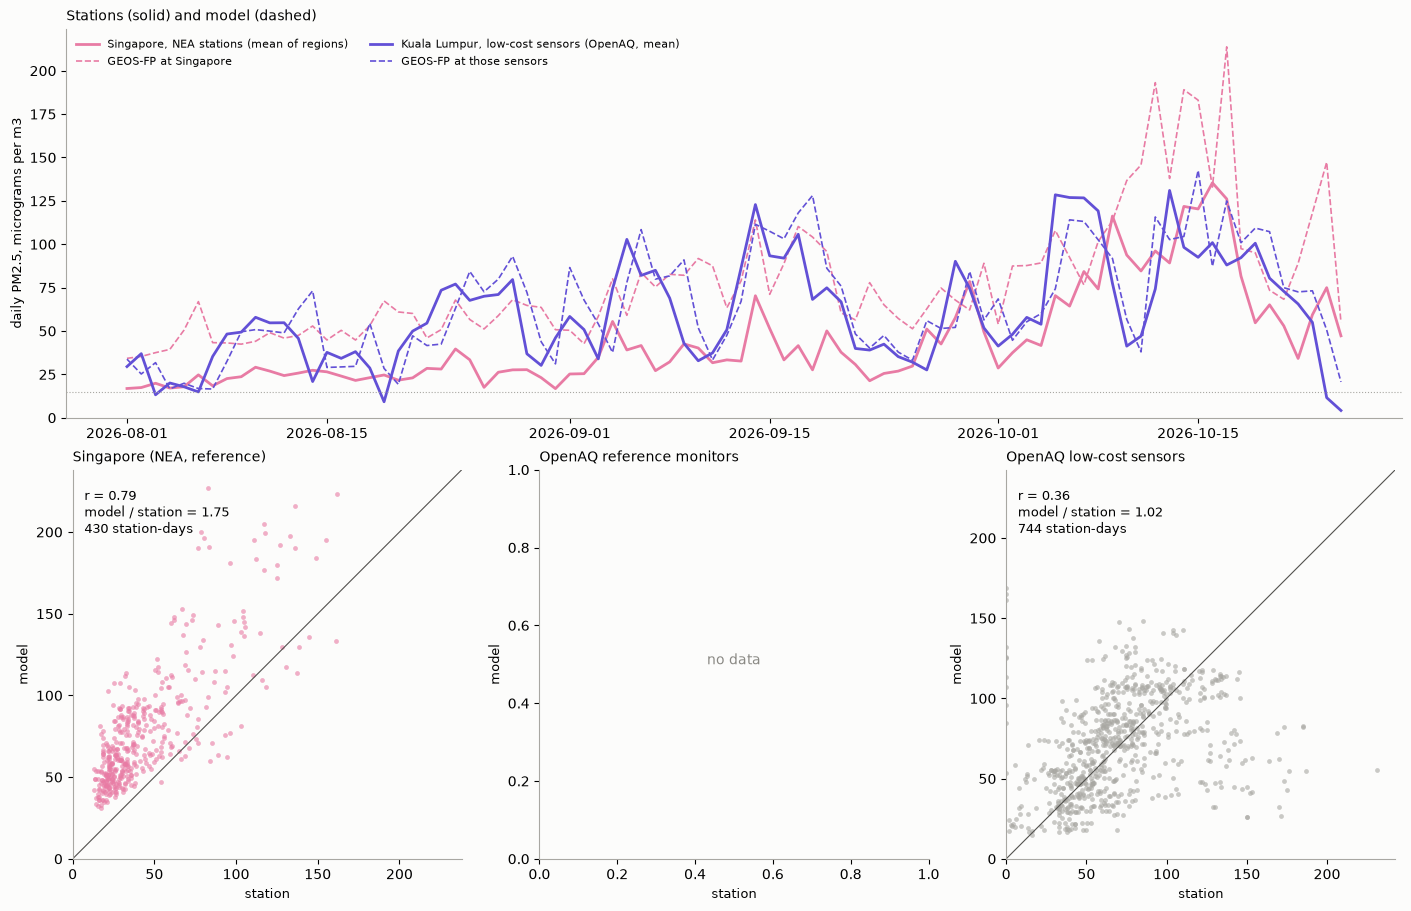

In [8]:
show_places = list(pairs_all.groupby("place")["date"].count().sort_values(ascending=False).index[:6])
fig = plt.figure(figsize=(14, 9), constrained_layout=True)
gs = fig.add_gridspec(2, 3)
ax_ts = fig.add_subplot(gs[0, :])
if len(sg_pairs):
    nat = sg_pairs.groupby("date")[["station_pm25", "model_pm25"]].mean()
    ax_ts.plot(nat.index, nat["station_pm25"], color="#e87ba4", lw=2, label="Singapore, NEA stations (mean of regions)")
    ax_ts.plot(nat.index, nat["model_pm25"], color="#e87ba4", lw=1.2, ls="--", label="GEOS-FP at Singapore")
kl = oa_pairs[oa_pairs["place"].str.startswith("Kuala Lumpur")]
if len(kl):
    kl_station = kl.groupby("date")[["station_pm25", "model_pm25"]].mean()
    kl_kind = "reference monitors" if kl["is_monitor"].all() else "low-cost sensors"
    ax_ts.plot(kl_station.index, kl_station["station_pm25"], color="#6250d6", lw=2, label=f"Kuala Lumpur, {kl_kind} (OpenAQ, mean)")
    ax_ts.plot(kl_station.index, kl_station["model_pm25"], color="#6250d6", lw=1.2, ls="--", label="GEOS-FP at those sensors")
ax_ts.axhline(15, color="#a8a7a2", lw=0.8, ls=":")
ax_ts.set_ylabel("daily PM2.5, micrograms per m3", fontsize=9)
ax_ts.set_ylim(bottom=0)
ax_ts.legend(frameon=False, fontsize=8, ncol=2)
ax_ts.set_title("Stations (solid) and model (dashed)", loc="left", fontsize=10)
ax_ts.spines[["top", "right"]].set_visible(False)
groups = [("Singapore (NEA, reference)", sg_pairs, "#e87ba4"), ("OpenAQ reference monitors", oa_pairs[oa_pairs["is_monitor"]], "#6250d6"), ("OpenAQ low-cost sensors", oa_pairs[~oa_pairs["is_monitor"]], "#a8a7a2")]
for k, (title, d, col) in enumerate(groups):
    ax = fig.add_subplot(gs[1, k])
    if len(d):
        ax.scatter(d["station_pm25"], d["model_pm25"], s=12, color=col, alpha=0.6, lw=0)
        top = float(np.nanmax([d["station_pm25"].max(), d["model_pm25"].max()])) * 1.05
        ax.plot([0, top], [0, top], color="#52514e", lw=0.8)
        r = d["station_pm25"].corr(d["model_pm25"])
        ratio = d["model_pm25"].mean() / d["station_pm25"].mean()
        ax.text(0.03, 0.95, f"r = {r:.2f}\nmodel / station = {ratio:.2f}\n{len(d)} station-days", transform=ax.transAxes, va="top", fontsize=9)
        ax.set_xlim(0, top)
        ax.set_ylim(0, top)
    else:
        ax.text(0.5, 0.5, "no data", transform=ax.transAxes, ha="center", color="#8a8984")
    ax.set_xlabel("station", fontsize=9)
    ax.set_ylabel("model", fontsize=9)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_aspect("equal")
    ax.spines[["top", "right"]].set_visible(False)
fig.savefig(FIG_DIR / "groundcheck.png", dpi=110)
plt.show()

___
**END**